In [6]:
import os

print(os.getcwd())
print(os.listdir('/content'))

/content
['.config', 'drive', 'sample_data']


In [7]:

from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [8]:

import pandas as pd

file_path = '/content/drive/MyDrive/messy_customer_sales_data.csv'

df = pd.read_csv(file_path)

df.head()


,Customer_ID,Name,Gender,Age,City,Signup_Date,Last_Purchase_Date,Purchase_Amount,Feedback_Score,Email,Phone_Number,Country
0,CUST4371,Paul Wilson,m,52.0,KOLKATA,2025-06-26,2025-05-17,26944.0,1.0,peckvictoria@example.com,2131107701,India
1,CUST5957,Jason Thomas,M,51.0 years,NaN,2021-02-17,2025-07-22,44152.0,2.0,owensanthony@example.com,1080761560,india
2,CUST3754,Brittney Martinez,F,62.0,hyderabad,2023-11-05,2024-12-08,31745.0,2.0,tara39@example.org,8981006345,India
3,CUST2934,Brenda Pierce,FEMALE,40.0,hyderabad,2022-03-13,2025-10-02,39674.0,1.0,berrynancy@example.org,8228064204,india
4,CUST5683,Matthew Carroll,f,41.0,CHENNAI,2024-04-05,2024-12-15,NaN,8.0,denise84@example.org,2665569480,India


## Step-By-Step Data Cleaning Process

### 1. Data Collection & Inspection
* **Type of data in each column:** (numerical, categorical, datetime, text)
* **Missing Values / Duplicate values**
* **Data types**
* **Inconsistencies**

In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10200 entries, 0 to 10199
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Customer_ID         9177 non-null   object 
 1   Name                10200 non-null  object 
 2   Gender              9174 non-null   object 
 3   Age                 9249 non-null   object 
 4   City                9184 non-null   object 
 5   Signup_Date         10200 non-null  object 
 6   Last_Purchase_Date  9188 non-null   object 
 7   Purchase_Amount     9179 non-null   float64
 8   Feedback_Score      9177 non-null   float64
 9   Email               10200 non-null  object 
 10  Phone_Number        10200 non-null  int64  
 11  Country             9468 non-null   object 
dtypes: float64(2), int64(1), object(9)
memory usage: 956.4+ KB


In [10]:
df.describe().round()

,Purchase_Amount,Feedback_Score,Phone_Number
count,9179.0,9177.0,1.020000e+04
mean,29090.0,5.0,4.979974e+09
std,208697.0,3.0,2.902593e+09
min,-500.0,1.0,9.208990e+05
25%,12295.0,3.0,2.449157e+09
50%,24330.0,5.0,4.988639e+09
75%,37130.0,8.0,7.510448e+09
max,9999999.0,10.0,9.994402e+09


In [11]:
df.isnull().sum()

,0
Customer_ID,1023
Name,0
Gender,1026
Age,951
City,1016
Signup_Date,0
Last_Purchase_Date,1012
Purchase_Amount,1021
Feedback_Score,1023
Email,0


In [12]:
df.isnull().sum()/len(df)*100

,0
Customer_ID,10.029412
Name,0.000000
Gender,10.058824
Age,9.323529
City,9.960784
Signup_Date,0.000000
Last_Purchase_Date,9.921569
Purchase_Amount,10.009804
Feedback_Score,10.029412
Email,0.000000


In [13]:
df.shape

(10200, 12)

In [14]:
df[df.duplicated()].shape

(15, 12)

In [15]:
df[df.duplicated()]

,Customer_ID,Name,Gender,Age,City,Signup_Date,Last_Purchase_Date,Purchase_Amount,Feedback_Score,Email,Phone_Number,Country
2032,CUST2755,Casey Campbell,male,NaN,Hyderabad,2023-12-01,2024-11-04,11778.0,3.0,joseph49@example.com,3844741384,India
3191,NaN,Travis Schneider,f,51.0,NaN,2025-04-20,2025-02-28,48750.0,5.0,bianca77@example.net,7623118785,India
4312,CUST8305,Stanley Cain,FEMALE,51.0,Bangalore,2023-08-14,2024-11-01,11432.0,6.0,calderonbrenda@example.org,4889366037,India
5611,CUST6288,Jonathon Kim,male,46.0,Chennai,2023-11-22,2025-03-21,3301.0,6.0,tparker@example.com,5266662560,India
5680,CUST2695,Lisa Durham,NaN,46.0,Chennai,2021-04-18,2024-10-10,6511.0,3.0,andrew34@example.com,2235480149,India
5899,CUST8841,Amanda Hill,NaN,34.0,chennai,2022-09-11,2025-03-13,42092.0,4.0,ryanriley@example.net,3466026146,India
6070,CUST10780,Emily Smith,NaN,23.0,Kolkata,2023-12-09,2024-10-28,18027.0,5.0,perezchristopher@example.com,3032282870,India
6240,CUST9745,David Morales,NaN,56.0,NaN,2023-02-18,2024-12-14,49107.0,7.0,juliaknapp@example.com,9436163110,India
6425,CUST4631,George Villa,m,26.0,Mumbai,2022-05-21,2025-06-17,NaN,8.0,davidmarquez@example.com,8869465862,India
6498,CUST1711,Stephanie Elliott,NaN,44.0,MUMBAI,2023-05-17,2025-07-12,11349.0,9.0,nfischer@example.com,3270872546,NaN


In [16]:
df['Customer_ID'].value_counts().head(10)

,count
Customer_ID,
CUST10800,2
CUST6588,2
CUST9062,2
CUST1852,2
CUST5472,2
CUST4160,2
CUST5019,2
CUST6288,2
CUST8174,2


In [17]:
df[df['Customer_ID'] == 'CUST3374']

,Customer_ID,Name,Gender,Age,City,Signup_Date,Last_Purchase_Date,Purchase_Amount,Feedback_Score,Email,Phone_Number,Country
2914,CUST3374,Timothy Wallace,m,58.0,Bangalore,2024-03-08,2025-08-21,45779.0,1.0,glenn95@example.org,9687701793,India
3047,CUST3374,Timothy Wallace,m,58.0,bangalore,2024-03-08,2025-08-21,45779.0,1.0,glenn95@example.org,9687701793,India


In [18]:
df[df['Customer_ID'] == 'CUST7749']

,Customer_ID,Name,Gender,Age,City,Signup_Date,Last_Purchase_Date,Purchase_Amount,Feedback_Score,Email,Phone_Number,Country
8150,CUST7749,Nancy Carter,female,21.0,NaN,2022-08-14,2024-10-11,42809.0,5.0,mollybryan@example.com,2483632670,InDia
8174,CUST7749,Nancy Carter,F,21.0,NaN,2022-08-14,2024-10-11,42809.0,5.0,mollybryan@example.com,2483632670,India


Problem is in data entry thats why duplicate rows are appearing.

In [19]:
for col in df.columns:
    if df[col].nunique() < 20:
        print(df[col].value_counts())
        print('-' * 50)

Gender
f         1184
M         1171
m         1163
F         1157
MALE      1131
female    1128
male      1121
FEMALE    1119
Name: count, dtype: int64
--------------------------------------------------
City
Kolkata       820
Mumbai        812
Chennai       784
Bangalore     773
Hyderabad     770
Delhi         763
CHENNAI       404
KOLKATA       395
MUMBAI        393
hyderabad     384
bangalore     383
DELHI         378
delhi         369
BANGALORE     363
HYDERABAD     360
mumbai        352
chennai       343
kolkata       338
Name: count, dtype: int64
--------------------------------------------------
Feedback_Score
2.0     952
4.0     947
7.0     938
6.0     927
3.0     913
8.0     912
1.0     907
9.0     903
10.0    901
5.0     877
Name: count, dtype: int64
--------------------------------------------------
Country
India    7132
IND       793
india     772
InDia     771
Name: count, dtype: int64
--------------------------------------------------


## 2. Handling Missing Values

* **Delete Rows / Columns:** Used when **more than 50%** of the data is missing.
* **Imputation (Filling Missing Values):**
  * **Numerical Columns:** Use **Mean**, **Median**, or **Mode**.
  * **Categorical Columns:** Use **Mode** or mark as **Unknown**.
  * **Datetime Columns:** Use **Forward fill** (`ffill`) or **Backward fill** (`bfill`).





In [20]:
df.dropna(subset=['Customer_ID'], inplace=True)

In [21]:
df.isnull().sum()

,0
Customer_ID,0
Name,0
Gender,934
Age,859
City,918
Signup_Date,0
Last_Purchase_Date,914
Purchase_Amount,927
Feedback_Score,905
Email,0


In [22]:
df['Age'].unique()

array(['52.0', '51.0 years', '62.0', '40.0', '41.0', nan, '18.0',
       '43.0 years', '40.0 years', '26.0', '32.0', '22.0', '59.0', '65.0',
       '61.0', '31.0', '54.0 years', '55.0', '69.0', '61.0 years', '24.0',
       '63.0', '19.0', '50.0', '56.0', '36.0', '68.0', '43.0', '38.0',
       '27.0', '57.0 years', '23.0', '25.0', '66.0', '28.0', '30.0',
       '46.0', '48.0', '20.0', '37.0', '67.0', '51.0', '35.0', '58.0',
       '29.0', 'nan years', '39.0', '49.0', '47.0', '42.0', '44.0',
       '64.0', '53.0', '60.0', '59.0 years', '45.0', '21.0', '34.0',
       '54.0', '48.0 years', '46.0 years', '33.0', '57.0', '30.0 years',
       '58.0 years', '35.0 years', '34.0 years', '69.0 years', '250',
       '19.0 years', '27.0 years', '53.0 years', '65.0 years',
       '66.0 years', '44.0 years', '49.0 years', '25.0 years',
       '23.0 years', '62.0 years', '41.0 years', '33.0 years',
       '28.0 years', '22.0 years', '20.0 years', '42.0 years',
       '45.0 years', '3', '63.0 years', '

This code cleans the Age column by extracting numbers from text, like 25 years to 25. If no number is found, it keeps the original value.

In [23]:
import re

def extract_age(age):
    age_num = re.findall('[0-9]+', str(age))
    if len(age_num) > 0:
        return age_num[0]
    else:
        return age

df['Age'] = df['Age'].apply(lambda x: extract_age(x))


In [24]:
df['Age'].unique()

array(['52', '51', '62', '40', '41', nan, '18', '43', '26', '32', '22',
       '59', '65', '61', '31', '54', '55', '69', '24', '63', '19', '50',
       '56', '36', '68', '38', '27', '57', '23', '25', '66', '28', '30',
       '46', '48', '20', '37', '67', '35', '58', '29', 'nan years', '39',
       '49', '47', '42', '44', '64', '53', '60', '45', '21', '34', '33',
       '250', '3', '10'], dtype=object)

In [25]:
df_age = df[df['Age']!= 'nan years']['Age']

In [26]:
age_median = int(df_age.dropna().astype('int64').median())

In [27]:
age_median

43

In [28]:
df.replace('nan years', age_median, inplace = True)

In [29]:
df['Age'].unique()

array(['52', '51', '62', '40', '41', nan, '18', '43', '26', '32', '22',
       '59', '65', '61', '31', '54', '55', '69', '24', '63', '19', '50',
       '56', '36', '68', '38', '27', '57', '23', '25', '66', '28', '30',
       '46', '48', '20', '37', '67', '35', '58', '29', 43, '39', '49',
       '47', '42', '44', '64', '53', '60', '45', '21', '34', '33', '250',
       '3', '10'], dtype=object)

In [30]:
df.isnull().sum()

,0
Customer_ID,0
Name,0
Gender,934
Age,859
City,918
Signup_Date,0
Last_Purchase_Date,914
Purchase_Amount,927
Feedback_Score,905
Email,0


In [31]:
df['Purchase_Amount'] = df['Purchase_Amount'].fillna(
    df['Purchase_Amount'].median()
)


In [32]:
df['Feedback_Score'] = df['Feedback_Score'].fillna(
    df['Feedback_Score'].mode()[0]
)

In [33]:
df.isnull().sum()

,0
Customer_ID,0
Name,0
Gender,934
Age,859
City,918
Signup_Date,0
Last_Purchase_Date,914
Purchase_Amount,0
Feedback_Score,0
Email,0


In [34]:
for col in ['Gender', 'City', 'Country']:
    df[col] = df[col].fillna(df[col].mode()[0])

In [35]:
df['Last_Purchase_Date'] = df['Last_Purchase_Date'].ffill()

## Step 3 - Fixing Inconsistent Formatting

* **Male, m, M, f, f, female** $\rightarrow$ 6 categories instead of 2 categories
* **Replace, lowercase**
* **Extra spaces:** `' AM'`, `'AM '` $\rightarrow$ `'AM'`

In [36]:
df['Gender'].unique()

array(['m ', 'M', 'F', 'FEMALE', 'f ', 'male', 'MALE', 'female'],
      dtype=object)

In [37]:
df['Gender'].str.lower()

,Gender
0,m
1,m
2,f
3,female
4,f
...,...
10194,f
10195,female
10197,m
10198,female


In [38]:
df['Gender'] = df['Gender'].str.lower().str.strip()

In [39]:
df['Gender'] = df['Gender'].replace({'m': 'male', 'f': 'female'})

In [40]:
df['Gender'].unique()

array(['male', 'female'], dtype=object)

In [41]:
df['City'] = df['City'].str.strip().str.lower()

In [42]:
df['City'].unique()

array(['kolkata', 'hyderabad', 'chennai', 'bangalore', 'mumbai', 'delhi'],
      dtype=object)

In [43]:
df['Country'].unique()

array(['India', 'india', 'InDia', 'IND'], dtype=object)

In [44]:
df['Country'] = df['Country'].str.lower()

In [45]:
df['Country'].replace({'ind':'india'}),

(0        india
 1        india
 2        india
 3        india
 4        india
          ...  
 10194    india
 10195    india
 10197    india
 10198    india
 10199    india
 Name: Country, Length: 9177, dtype: object,)

## 4. Handling duplicates

* Remove duplicate records / rows.
* Check for primary key.
* Remove near duplicate records

In [46]:
df[df.duplicated()].shape

(137, 12)

In [47]:
df.drop_duplicates(inplace=True)

In [48]:
df[df.duplicated()].shape

(0, 12)

In [49]:
df['Customer_ID'].value_counts()

,count
Customer_ID,
CUST9950,2
CUST9112,2
CUST4492,2
CUST1002,2
CUST8308,2
...,...
CUST1674,1
CUST7314,1
CUST5221,1


In [50]:
df.drop_duplicates(subset=['Customer_ID'], keep = 'first', inplace = True)

## 5. Correcting Data Types

After handling missing values and duplicates, ensuring that each column has the correct data type is essential for analysis and modeling. Incorrect data types can cause calculation errors, incorrect groupings, or high memory usage.

Common data type conversions in Pandas:
* **Numeric** $\rightarrow$ `int` / `float`
* **Categorical** $\rightarrow$ `object` (or `category`)
* **Date/Time** $\rightarrow$ `datetime`

In [51]:
df['Signup_Date'] = pd.to_datetime(df['Signup_Date'])

In [52]:
df['Last_Purchase_Date'] = pd.to_datetime(df['Last_Purchase_Date'])

In [53]:
df.dtypes

,0
Customer_ID,object
Name,object
Gender,object
Age,object
City,object
Signup_Date,datetime64[ns]
Last_Purchase_Date,datetime64[ns]
Purchase_Amount,float64
Feedback_Score,float64
Email,object


## 6. Handling Outliers

Outliers are data points that differ significantly from other observations. Before handling them, it's important to identify their nature:

* **Genuine Outliers:** Extreme values that are real and valid data points (e.g., a very high income).
* **Errors:** Mistakes in data entry, measurement, or collection.

### Common Approaches to Handle Outliers:
* **Remove Outliers / Statistical Methods (IQR, Z-score):** Filter or drop values beyond a certain threshold using the Interquartile Range (IQR) or Z-score.
* **Domain Knowledge:** Use industry expertise to decide whether to keep, cap, or treat the values.
* **Transforming Data:** Apply mathematical transformations (like log transformation) to reduce the skewness caused by outliers.

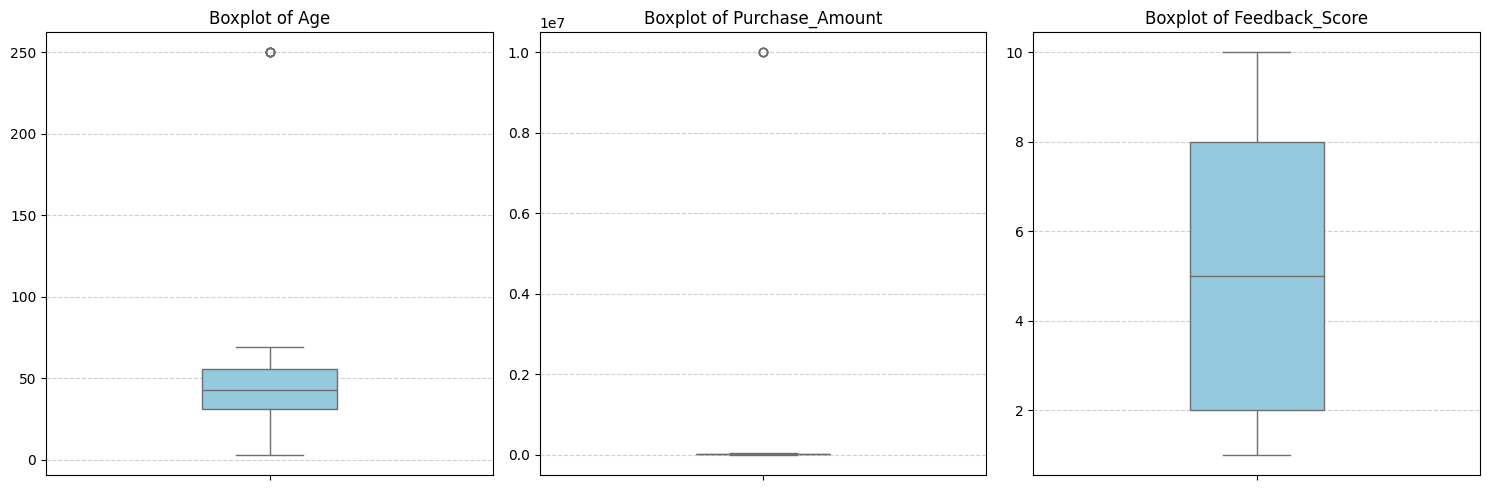

In [54]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

cols = ['Age', 'Purchase_Amount', 'Feedback_Score']

for col in cols:
    df[col] = pd.to_numeric(df[col], errors='coerce')

plt.figure(figsize=(15, 5))

for i, col in enumerate(cols, 1):
    plt.subplot(1, 3, i)
    sns.boxplot(y=df[col], color='skyblue', width=0.3)
    plt.title(f'Boxplot of {col}')
    plt.ylabel('')
    plt.grid(axis='y', linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

SciPy is a Python library used for scientific and mathematical calculations.

In [55]:
from scipy import stats

Z-score tells us how far a value is from the average.

In [59]:
import numpy as np
z_scores = np.abs(stats.zscore(df[['Age', 'Purchase_Amount']]))

In [60]:
df_clean = df[~(z_scores>3).any(axis = 1)]

In [61]:
df_clean.shape

(8996, 12)

## 1. Distribution of Purchase Amounts

**Observation:** This chart shows how customer purchase amounts are distributed.

Customer spending is mostly spread out evenly, with a massive spike around ₹24,000 because missing values were filled with the median amount during data cleaning.

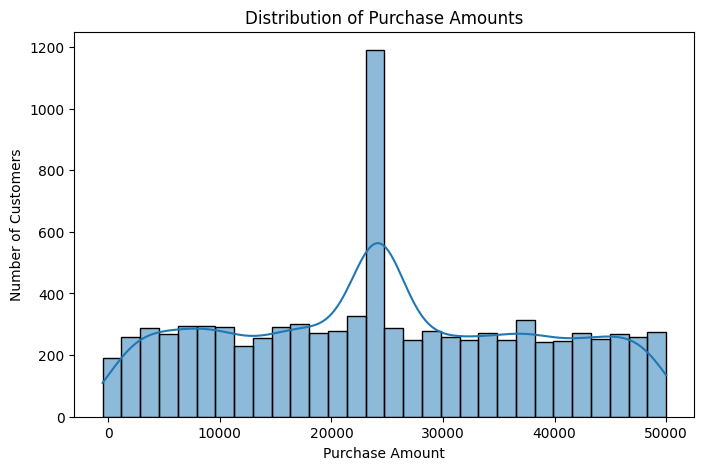

In [62]:

plt.figure(figsize=(8, 5))
sns.histplot(data=df_clean, x="Purchase_Amount", bins=30, kde=True)
plt.title("Distribution of Purchase Amounts")
plt.xlabel("Purchase Amount")
plt.ylabel("Number of Customers")
plt.show()


## 2. Average Purchase Amount by City

**Observation:** This chart compares average purchase amounts across cities.

The average purchase amount is nearly identical (around ₹24,000–₹25,000) in all cities, meaning location does not change spending habits.

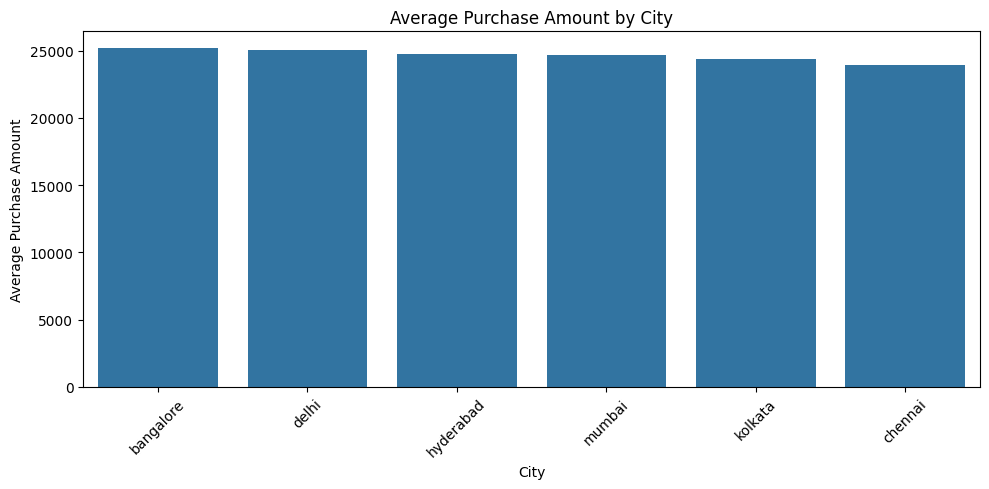

In [63]:

city_sales = df_clean.groupby("City")["Purchase_Amount"].mean().sort_values(ascending=False)

plt.figure(figsize=(10, 5))
sns.barplot(x=city_sales.index, y=city_sales.values)
plt.title("Average Purchase Amount by City")
plt.xlabel("City")
plt.ylabel("Average Purchase Amount")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


## Scatter Plot (Age vs. Purchase Amount by Gender)

**Observation** Uses dots on a grid to see if age or gender affects how much money people spend.

Age and gender do not have a strong link to purchase amounts; customers of all ages spend across all price tiers equally.

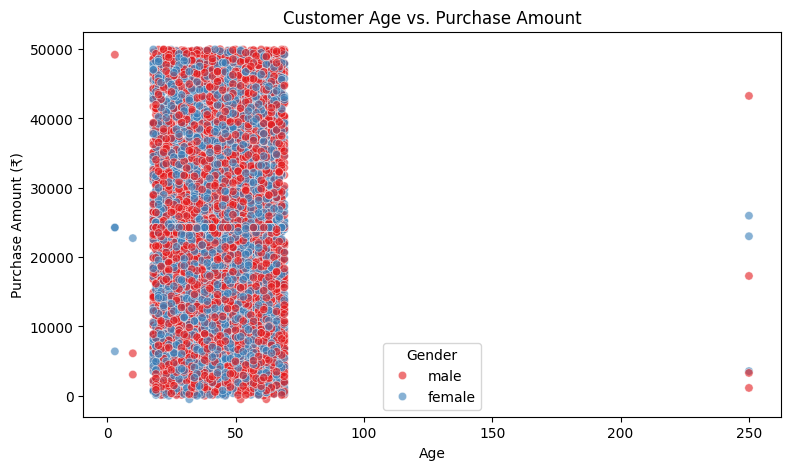

In [64]:
plt.figure(figsize=(9, 5))
sns.scatterplot(data=df_clean, x='Age', y='Purchase_Amount', hue='Gender', alpha=0.6, palette='Set1')

plt.title('Customer Age vs. Purchase Amount')
plt.xlabel('Age')
plt.ylabel('Purchase Amount (₹)')
plt.show()

## 2. Box Plot (Purchase Amount across Feedback Scores)

**Observation:** This chart shows the middle spending range for each customer feedback rating (1 to 10).

The average purchase amount is nearly identical (around ₹24,000–₹25,000) in all cities, meaning location does not change spending habits.

/tmp/ipykernel_2331/1246023984.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_clean, x='Feedback_Score', y='Purchase_Amount', palette='coolwarm')


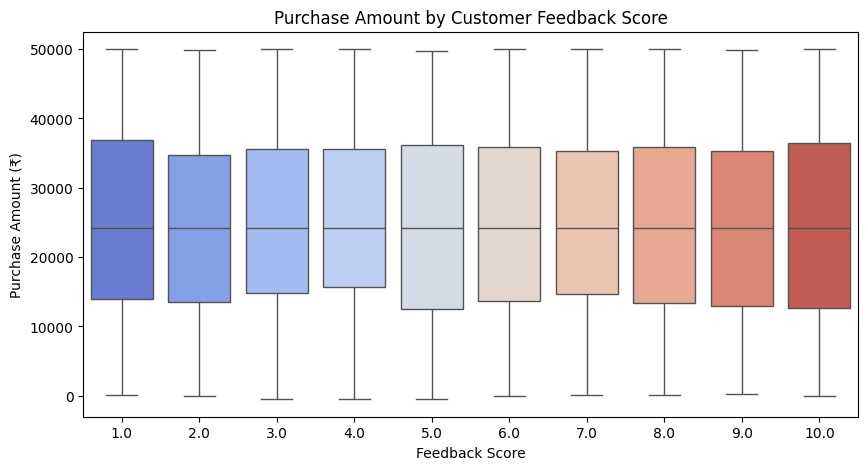

In [65]:
plt.figure(figsize=(10, 5))
sns.boxplot(data=df_clean, x='Feedback_Score', y='Purchase_Amount', palette='coolwarm' )

plt.title('Purchase Amount by Customer Feedback Score')
plt.xlabel('Feedback Score')
plt.ylabel('Purchase Amount (₹)')
plt.show()

## 2. Correlation Heatmap (Numerical Variables)


**Observation:** This chart uses color-coded boxes to show if numerical columns move together.

The numbers are all close to 0, proving there are no hidden direct mathematical relationships between age, spending, and feedback scores.

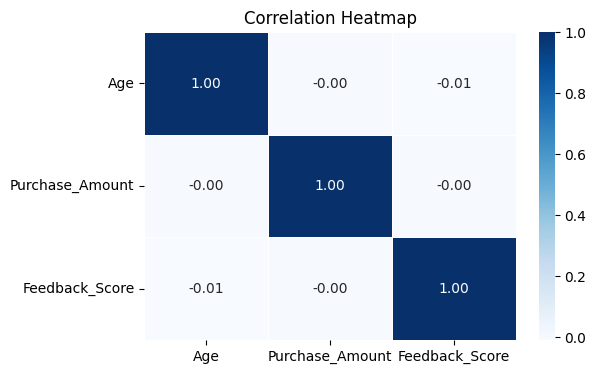

In [66]:
plt.figure(figsize=(6, 4))
numeric_cols = df_clean[['Age', 'Purchase_Amount', 'Feedback_Score']]
correlation_matrix = numeric_cols.corr()

sns.heatmap(correlation_matrix, annot=True, cmap='Blues', fmt='.2f', linewidths=0.5)

plt.title('Correlation Heatmap')
plt.show()